In [3]:
import numpy as np
import polars as pl 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import root_mean_squared_error

In [11]:
def load_real_data(path):
    exp_data = pl.read_excel(path, engine="calamine")
    exp_compositions = exp_data.select([ 'FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 'FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H'])
    exp_compositions_np = exp_compositions.to_numpy()
    
    return exp_compositions_np

def load_predicted_data(path):
    
    calculated_data = pl.read_excel(path, engine="calamine")
    calculated_data_np = calculated_data.to_numpy()
    return calculated_data_np 

def error_graph(exp_compositions_np, calculated_data_np):
    
    sns.set_theme(rc={'figure.figsize':(10,5)})
    sns.set_style("whitegrid")

    sns.scatterplot(x = range(313), y =  np.sqrt(np.mean((exp_compositions_np[0:313, :] - calculated_data_np[0:313, :])**2, 1)), 
                    facecolor = "none", edgecolor = "black", label = "FAME/FAEE-Alcohol-Glycerol")

    sns.scatterplot(x = range(312, 337, 1), y =  np.sqrt(np.mean((exp_compositions_np[312:337, :] - calculated_data_np[312:337, :])**2, 1)), 
                    facecolor = "none", edgecolor = "Orange", label = "FAME/FAEE-Alcohol-Water")

    sns.scatterplot(x = range(337, 402, 1), y =  np.sqrt(np.mean((exp_compositions_np[337:402, :] - calculated_data_np[337:402, :])**2, 1)), 
                    facecolor = "none", edgecolor = "Black")

    sns.scatterplot(x = range(402, 498, 1), y =  np.sqrt(np.mean((exp_compositions_np[402:498, :] - calculated_data_np[402:498, :])**2, 1)), 
                    facecolor = "none", edgecolor = "Orange")

    sns.scatterplot(x = range(498, 895, 1), y =  np.sqrt(np.mean((exp_compositions_np[498:895, :] - calculated_data_np[498:895, :])**2, 1)), 
                    facecolor = "none", edgecolor = "blue", label = "Oil-Alcohol-Acid/Water")

    sns.scatterplot(x = range(895, 898, 1), y =  np.sqrt(np.mean((exp_compositions_np[895:898, :] - calculated_data_np[895:898, :])**2, 1)), 
                    facecolor = "none", edgecolor = "black")

    sns.scatterplot(x = range(898, 908, 1), y =  np.sqrt(np.mean((exp_compositions_np[898:908, :] - calculated_data_np[898:908, :])**2, 1)), 
                    facecolor = "none", edgecolor = "blue")

    sns.scatterplot(x = range(908, 964, 1), y =  np.sqrt(np.mean((exp_compositions_np[908:964, :] - calculated_data_np[908:964, :])**2, 1)), 
                    facecolor = "none", edgecolor = "black")

    sns.scatterplot(x = range(964, 984, 1), y =  np.sqrt(np.mean((exp_compositions_np[964:984, :] - calculated_data_np[964:984, :]), 1)), 
                    facecolor = "none", edgecolor = "green", label = "Oil-Alcohol-Acid/Water-DAG/MAG")

    sns.scatterplot(x = range(984, 1029, 1), y =  np.sqrt(np.mean((exp_compositions_np[984:1029, :] - calculated_data_np[984:1029, :])**2, 1)), 
                    facecolor = "none", edgecolor = "black")

    sns.scatterplot(x = range(1029, 1042, 1), y =  np.sqrt(np.mean((exp_compositions_np[1029:1042, :] - calculated_data_np[1029:1042, :])**2, 1)), 
                    facecolor = "none", edgecolor = "blue")

    test_RMSE = round(root_mean_squared_error(exp_compositions_np[:897, :], calculated_data_np[:897, :]), 4)
    validate_RMSE = round(root_mean_squared_error(exp_compositions_np[896:, :], calculated_data_np[896:, :]), 4)
    plt.text(2, 0.3, f'Test RMSE: {test_RMSE}', fontsize=10, color='red')
    plt.text(970, 0.25, f'Validate RMSE: {validate_RMSE}', fontsize=10, color='red')

    plt.axvline(x=896, color='red', linestyle='--', linewidth=2)
    plt.legend(loc = "upper right")
    plt.xlabel("Tie Line", fontsize=14)
    plt.ylabel("RMSE per tie line", fontsize=14)
    sns.set_context("talk", font_scale=2)  

    plt.show() 
    
def deviation_grahp(exp_compositions_np, calculated_data_np):
    sns.set_theme(rc={'figure.figsize':(10,5)})
    sns.set_style("whitegrid")

    sns.lineplot(x = [0,1], y=[0,1], color = "black")
    sns.scatterplot(x = calculated_data_np[:, 0], y = exp_compositions_np[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")
    sns.scatterplot(x = calculated_data_np[:, 8], y = exp_compositions_np[:, 8], facecolor = "none", edgecolor = "red")

    sns.scatterplot(x = calculated_data_np[:, 1], y = exp_compositions_np[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")
    sns.scatterplot(x = calculated_data_np[:, 9], y = exp_compositions_np[:, 9], facecolor = "none", edgecolor = "blue")

    sns.scatterplot(x = calculated_data_np[:, 2], y = exp_compositions_np[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")
    sns.scatterplot(x = calculated_data_np[:, 10], y = exp_compositions_np[:, 10], facecolor = "none", edgecolor = "green")

    sns.scatterplot(x = calculated_data_np[:, 3], y = exp_compositions_np[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")
    sns.scatterplot(x = calculated_data_np[:, 11], y = exp_compositions_np[:, 11], facecolor = "none", edgecolor = "orange")

    sns.scatterplot(x = calculated_data_np[:, 4], y = exp_compositions_np[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")
    sns.scatterplot(x = calculated_data_np[:, 12], y = exp_compositions_np[:, 12], facecolor = "none", edgecolor = "goldenrod")

    sns.scatterplot(x = calculated_data_np[:, 5], y = exp_compositions_np[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")
    sns.scatterplot(x = calculated_data_np[:, 13], y = exp_compositions_np[:, 13], facecolor = "none", edgecolor = "darkviolet")

    sns.scatterplot(x = calculated_data_np[:, 6], y = exp_compositions_np[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")
    sns.scatterplot(x = calculated_data_np[:, 14], y = exp_compositions_np[:, 14], facecolor = "none", edgecolor = "darkcyan")

    sns.scatterplot(x = calculated_data_np[:, 7], y = exp_compositions_np[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")
    sns.scatterplot(x = calculated_data_np[:, 15], y = exp_compositions_np[:, 15], facecolor = "none", edgecolor = "magenta")

    plt.xlabel("Experimental composition (%w)", fontsize=14)
    plt.ylabel("Calcualted composition (%w)", fontsize=14)
    sns.set_context("talk", font_scale=2) 

    plt.show()

In [2]:
exp_data = pl.read_excel(r"D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\ExperimentalData\data\refined_lle_data_v4.xlsx", engine="calamine")
exp_compositions = exp_data.select([ 'FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 'FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H'])
exp_compositions_np = exp_compositions.to_numpy()

#### Unifac Base Case

In [12]:
calculated_data = pl.read_excel("Unifac_Base_Case_II.xlsx", engine="calamine")

In [13]:
calculated_data_np = calculated_data.to_numpy()

In [14]:
total_error = root_mean_squared_error(exp_compositions_np, calculated_data_np)
print("RMSE: ", total_error)

RMSE:  0.07324470535699237


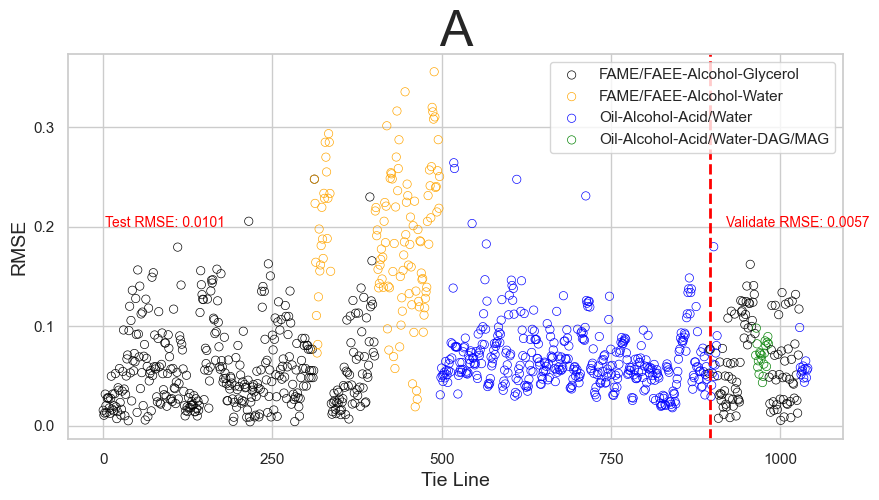

In [15]:
sns.set_theme(rc={'figure.figsize':(10,5)})
sns.set_style("whitegrid")

sns.scatterplot(x = range(313), y =  np.sqrt(np.mean((exp_compositions_np[0:313, :] - calculated_data_np[0:313, :])**2, 1)), 
                facecolor = "none", edgecolor = "black", label = "FAME/FAEE-Alcohol-Glycerol")

sns.scatterplot(x = range(312, 337, 1), y =  np.sqrt(np.mean((exp_compositions_np[312:337, :] - calculated_data_np[312:337, :])**2, 1)), 
                facecolor = "none", edgecolor = "Orange", label = "FAME/FAEE-Alcohol-Water")

sns.scatterplot(x = range(337, 402, 1), y =  np.sqrt(np.mean((exp_compositions_np[337:402, :] - calculated_data_np[337:402, :])**2, 1)), 
                facecolor = "none", edgecolor = "Black")

sns.scatterplot(x = range(402, 498, 1), y =  np.sqrt(np.mean((exp_compositions_np[402:498, :] - calculated_data_np[402:498, :])**2, 1)), 
                facecolor = "none", edgecolor = "Orange")

sns.scatterplot(x = range(498, 895, 1), y =  np.sqrt(np.mean((exp_compositions_np[498:895, :] - calculated_data_np[498:895, :])**2, 1)), 
                facecolor = "none", edgecolor = "blue", label = "Oil-Alcohol-Acid/Water")

sns.scatterplot(x = range(895, 898, 1), y =  np.sqrt(np.mean((exp_compositions_np[895:898, :] - calculated_data_np[895:898, :])**2, 1)), 
                facecolor = "none", edgecolor = "black")

sns.scatterplot(x = range(898, 908, 1), y =  np.sqrt(np.mean((exp_compositions_np[898:908, :] - calculated_data_np[898:908, :])**2, 1)), 
                facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = range(908, 964, 1), y =  np.sqrt(np.mean((exp_compositions_np[908:964, :] - calculated_data_np[908:964, :])**2, 1)), 
                facecolor = "none", edgecolor = "black")

sns.scatterplot(x = range(964, 984, 1), y =  np.sqrt(np.mean((exp_compositions_np[964:984, :] - calculated_data_np[964:984, :])**2, 1)), 
                facecolor = "none", edgecolor = "green", label = "Oil-Alcohol-Acid/Water-DAG/MAG")

sns.scatterplot(x = range(984, 1029, 1), y =  np.sqrt(np.mean((exp_compositions_np[984:1029, :] - calculated_data_np[984:1029, :])**2, 1)), 
                facecolor = "none", edgecolor = "black")

sns.scatterplot(x = range(1029, 1042, 1), y =  np.sqrt(np.mean((exp_compositions_np[1029:1042, :] - calculated_data_np[1029:1042, :])**2, 1)), 
                facecolor = "none", edgecolor = "blue")

test_RMSE = round(np.mean((exp_compositions_np[:897, :] - calculated_data_np[:897, :])**2), 4)
validate_RMSE = round(np.mean((exp_compositions_np[896:, :] - calculated_data_np[896:, :])**2), 4)
plt.text(2, 0.2, f'Test RMSE: {test_RMSE}', fontsize=10, color='red')
plt.text(920, 0.2, f'Validate RMSE: {validate_RMSE}', fontsize=10, color='red')

plt.axvline(x=896, color='red', linestyle='--', linewidth=2)
plt.legend(loc = "upper right")
plt.xlabel("Tie Line", fontsize=14)
plt.ylabel("RMSE", fontsize=14)
sns.set_context("talk", font_scale=2)
plt.title("A")
plt.savefig('UNIFAC_RMSE.png', dpi=1000, bbox_inches='tight')
plt.show()



In [16]:
non_zero_mask = np.any(calculated_data_np != 0, axis=1) & np.any(exp_compositions_np != 0, axis=1)
calculated_data_np = calculated_data_np[non_zero_mask]
exp_compositions_np = exp_compositions_np[non_zero_mask]

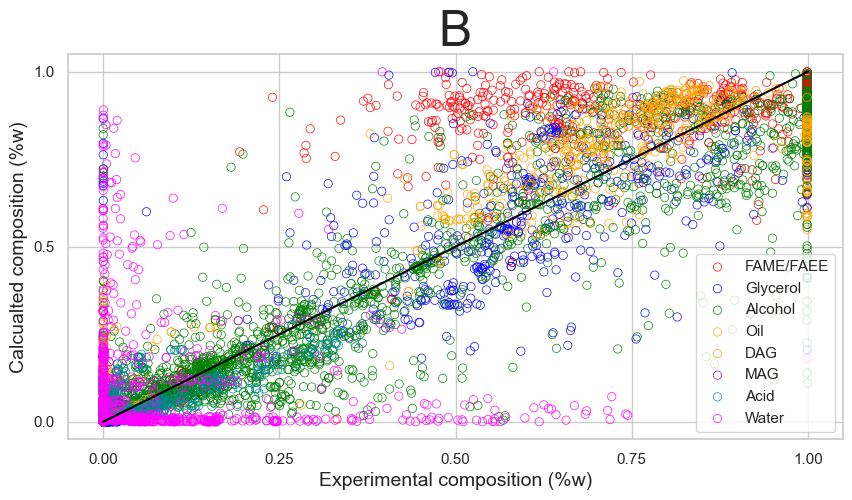

In [17]:
sns.set_theme(rc={'figure.figsize':(10,5)})
sns.set_style("whitegrid")
sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = calculated_data_np[:, 0], y = exp_compositions_np[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")
sns.scatterplot(x = calculated_data_np[:, 8], y = exp_compositions_np[:, 8], facecolor = "none", edgecolor = "red")

sns.scatterplot(x = calculated_data_np[:, 1], y = exp_compositions_np[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")
sns.scatterplot(x = calculated_data_np[:, 9], y = exp_compositions_np[:, 9], facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = calculated_data_np[:, 2], y = exp_compositions_np[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")
sns.scatterplot(x = calculated_data_np[:, 10], y = exp_compositions_np[:, 10], facecolor = "none", edgecolor = "green")

sns.scatterplot(x = calculated_data_np[:, 3], y = exp_compositions_np[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")
sns.scatterplot(x = calculated_data_np[:, 11], y = exp_compositions_np[:, 11], facecolor = "none", edgecolor = "orange")

sns.scatterplot(x = calculated_data_np[:, 4], y = exp_compositions_np[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")
sns.scatterplot(x = calculated_data_np[:, 12], y = exp_compositions_np[:, 12], facecolor = "none", edgecolor = "goldenrod")

sns.scatterplot(x = calculated_data_np[:, 5], y = exp_compositions_np[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")
sns.scatterplot(x = calculated_data_np[:, 13], y = exp_compositions_np[:, 13], facecolor = "none", edgecolor = "darkviolet")

sns.scatterplot(x = calculated_data_np[:, 6], y = exp_compositions_np[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")
sns.scatterplot(x = calculated_data_np[:, 14], y = exp_compositions_np[:, 14], facecolor = "none", edgecolor = "darkcyan")

sns.scatterplot(x = calculated_data_np[:, 7], y = exp_compositions_np[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")
sns.scatterplot(x = calculated_data_np[:, 15], y = exp_compositions_np[:, 15], facecolor = "none", edgecolor = "magenta")

plt.xlabel("Experimental composition (%w)", fontsize=14)
plt.ylabel("Calcualted composition (%w)", fontsize=14)
sns.set_context("talk", font_scale=2) 
plt.title("B")
plt.savefig('UNIFAC_CORR.png', dpi=1000, bbox_inches='tight')
plt.show()

#### Unifac Base Case II (After remove exp 47)

In [10]:
calculated_data = pl.read_excel("Unifac_Base_Case_II.xlsx", engine="calamine")

In [11]:
calculated_data_np = calculated_data.to_numpy()

In [12]:
total_error = np.sum((exp_compositions_np - calculated_data_np)**2)/exp_compositions.shape[0]*100
print("El error total es: ", total_error)

El error total es:  15.177517780644692


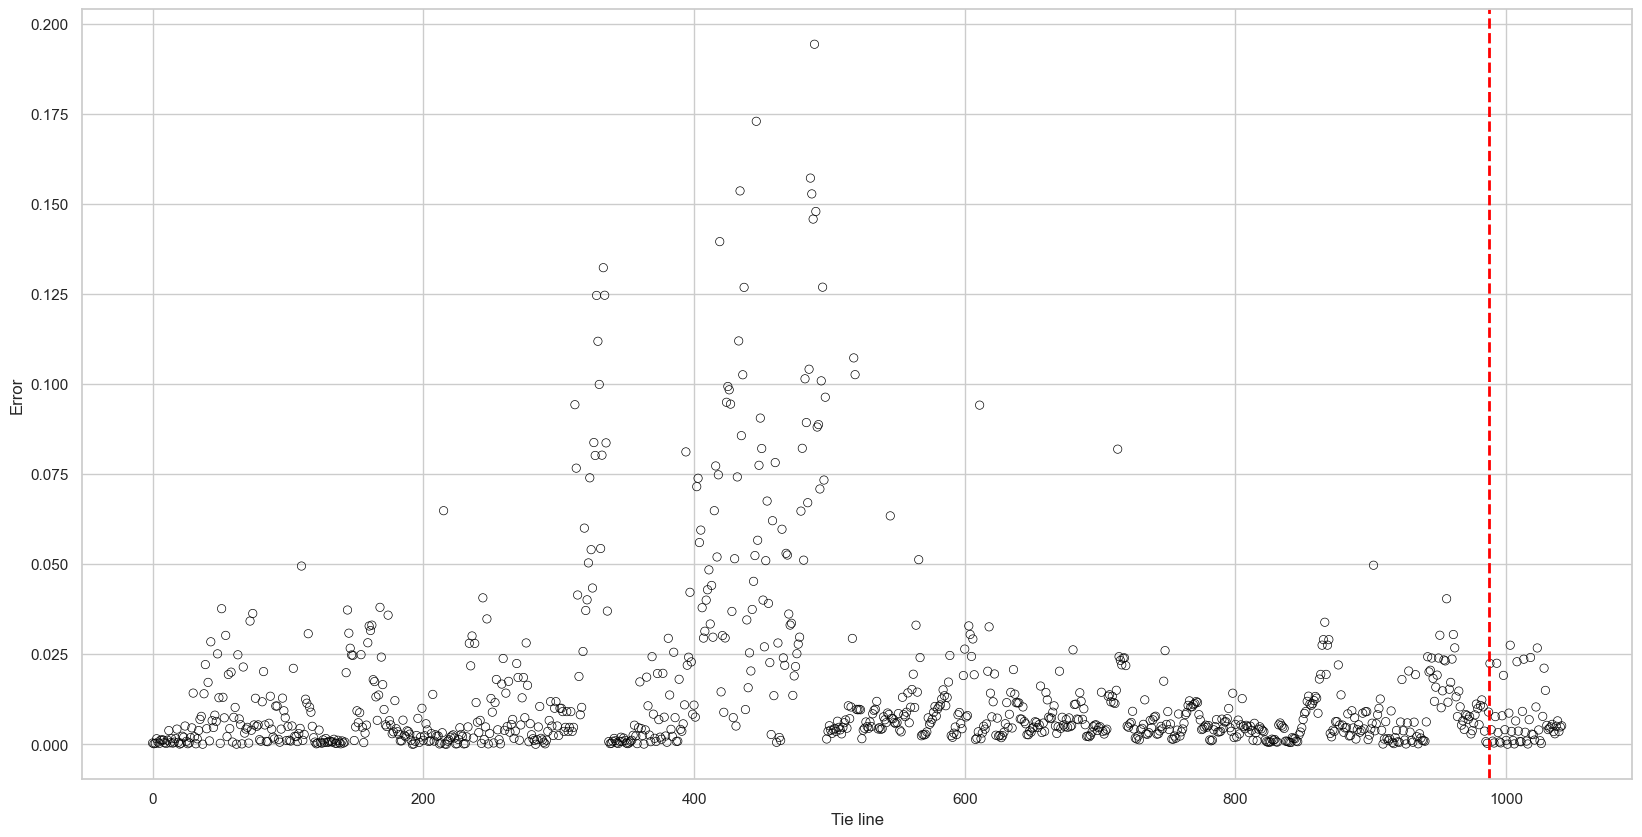

In [13]:
sns.set_theme(rc={'figure.figsize':(20,10)})
sns.set_style("whitegrid")
sns.scatterplot(x = range(exp_compositions_np.shape[0]), y =  np.sum((exp_compositions_np - calculated_data_np)**2, 1)/exp_compositions.shape[0]*100, 
                facecolor = "none", edgecolor = "black").set(xlabel = "Tie line", ylabel="Error")
plt.axvline(x=987, color='red', linestyle='--', linewidth=2)
plt.show()

In [14]:
non_zero_mask = np.any(calculated_data_np != 0, axis=1) & np.any(exp_compositions_np != 0, axis=1)
calculated_data_np = calculated_data_np[non_zero_mask]
exp_compositions_np = exp_compositions_np[non_zero_mask]

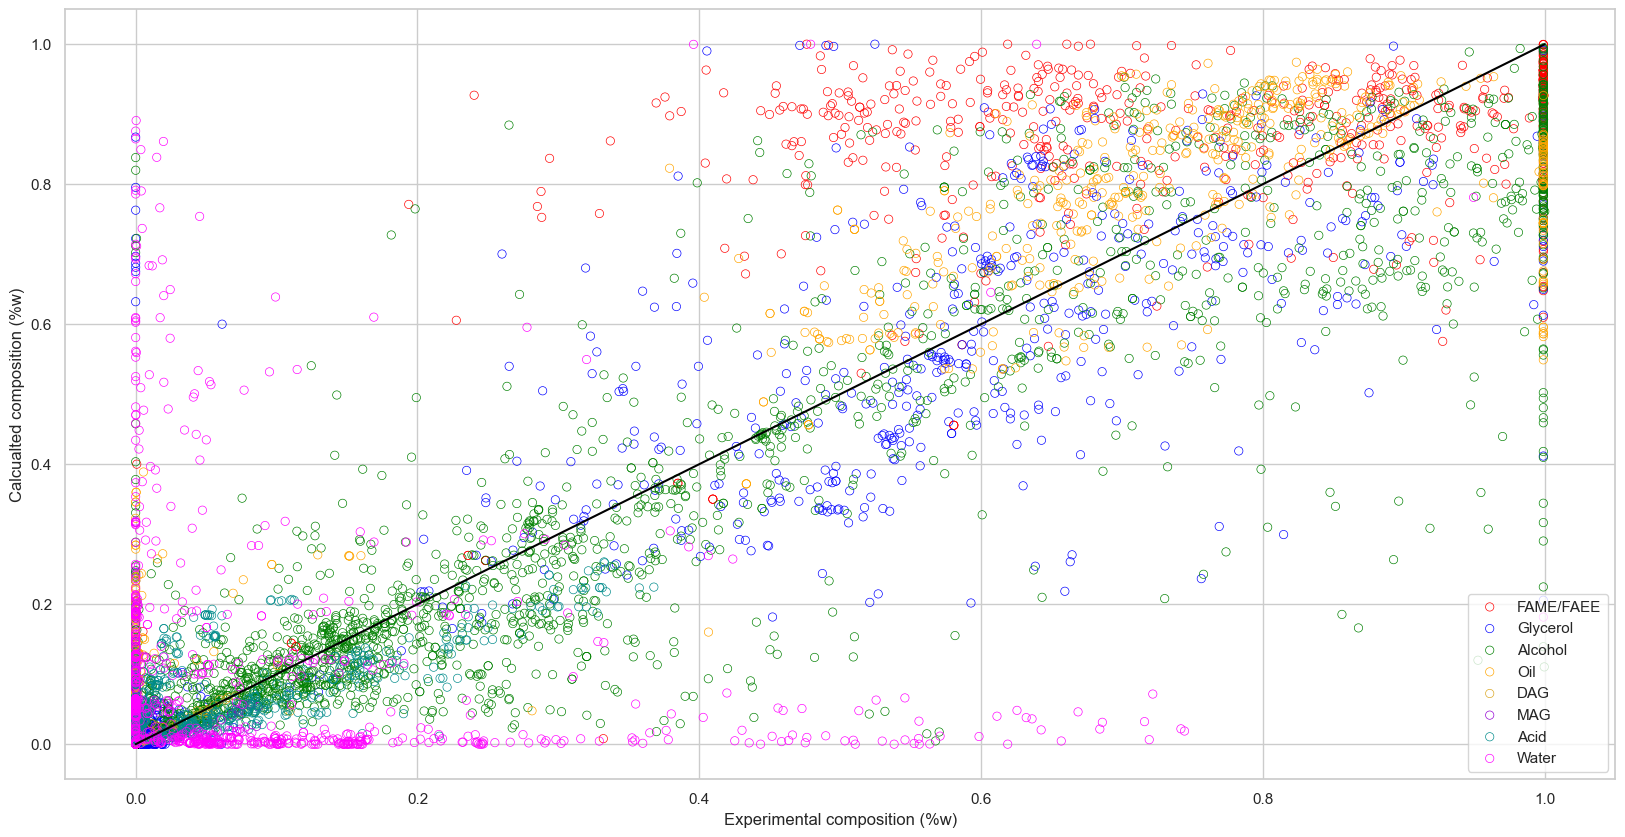

In [15]:
sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = calculated_data_np[:, 0], y = exp_compositions_np[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")
sns.scatterplot(x = calculated_data_np[:, 8], y = exp_compositions_np[:, 8], facecolor = "none", edgecolor = "red")

sns.scatterplot(x = calculated_data_np[:, 1], y = exp_compositions_np[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")
sns.scatterplot(x = calculated_data_np[:, 9], y = exp_compositions_np[:, 9], facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = calculated_data_np[:, 2], y = exp_compositions_np[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")
sns.scatterplot(x = calculated_data_np[:, 10], y = exp_compositions_np[:, 10], facecolor = "none", edgecolor = "green")

sns.scatterplot(x = calculated_data_np[:, 3], y = exp_compositions_np[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")
sns.scatterplot(x = calculated_data_np[:, 11], y = exp_compositions_np[:, 11], facecolor = "none", edgecolor = "orange")

sns.scatterplot(x = calculated_data_np[:, 4], y = exp_compositions_np[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")
sns.scatterplot(x = calculated_data_np[:, 12], y = exp_compositions_np[:, 12], facecolor = "none", edgecolor = "goldenrod")

sns.scatterplot(x = calculated_data_np[:, 5], y = exp_compositions_np[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")
sns.scatterplot(x = calculated_data_np[:, 13], y = exp_compositions_np[:, 13], facecolor = "none", edgecolor = "darkviolet")

sns.scatterplot(x = calculated_data_np[:, 6], y = exp_compositions_np[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")
sns.scatterplot(x = calculated_data_np[:, 14], y = exp_compositions_np[:, 14], facecolor = "none", edgecolor = "darkcyan")

sns.scatterplot(x = calculated_data_np[:, 7], y = exp_compositions_np[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")
sns.scatterplot(x = calculated_data_np[:, 15], y = exp_compositions_np[:, 15], facecolor = "none", edgecolor = "magenta").set(xlabel = "Experimental composition (%w)", ylabel = "Calcualted composition (%w)")
plt.show()

#### Evaluation of new params V1

In [10]:
calculated_data = pl.read_excel("results/UDortmund_Results.xlsx", engine="calamine")

In [11]:
calculated_data_np = calculated_data.to_numpy()

In [12]:
total_error = np.sum((exp_compositions_np - calculated_data_np)**2)/exp_compositions.shape[0]*100
print("El error total es: ", total_error)

El error total es:  17.07625905051554


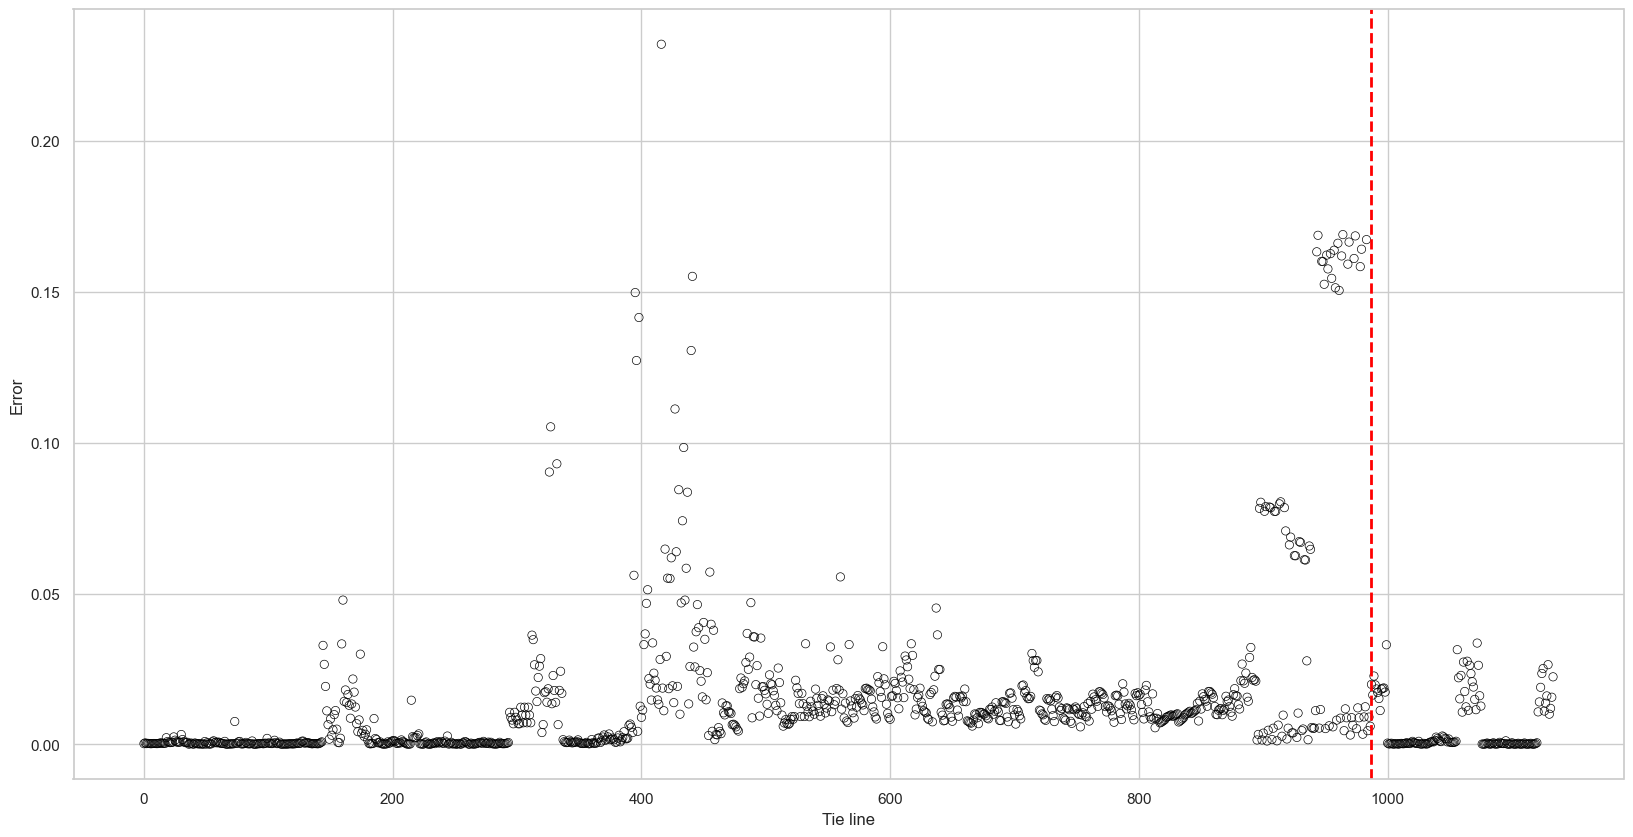

In [13]:
sns.set_theme(rc={'figure.figsize':(20,10)})
sns.set_style("whitegrid")
sns.scatterplot(x = range(exp_compositions_np.shape[0]), y =  np.sum((exp_compositions_np - calculated_data_np)**2, 1)/exp_compositions.shape[0]*100, 
                facecolor = "none", edgecolor = "black").set(xlabel = "Tie line", ylabel="Error")
plt.axvline(x=987, color='red', linestyle='--', linewidth=2)
plt.show()

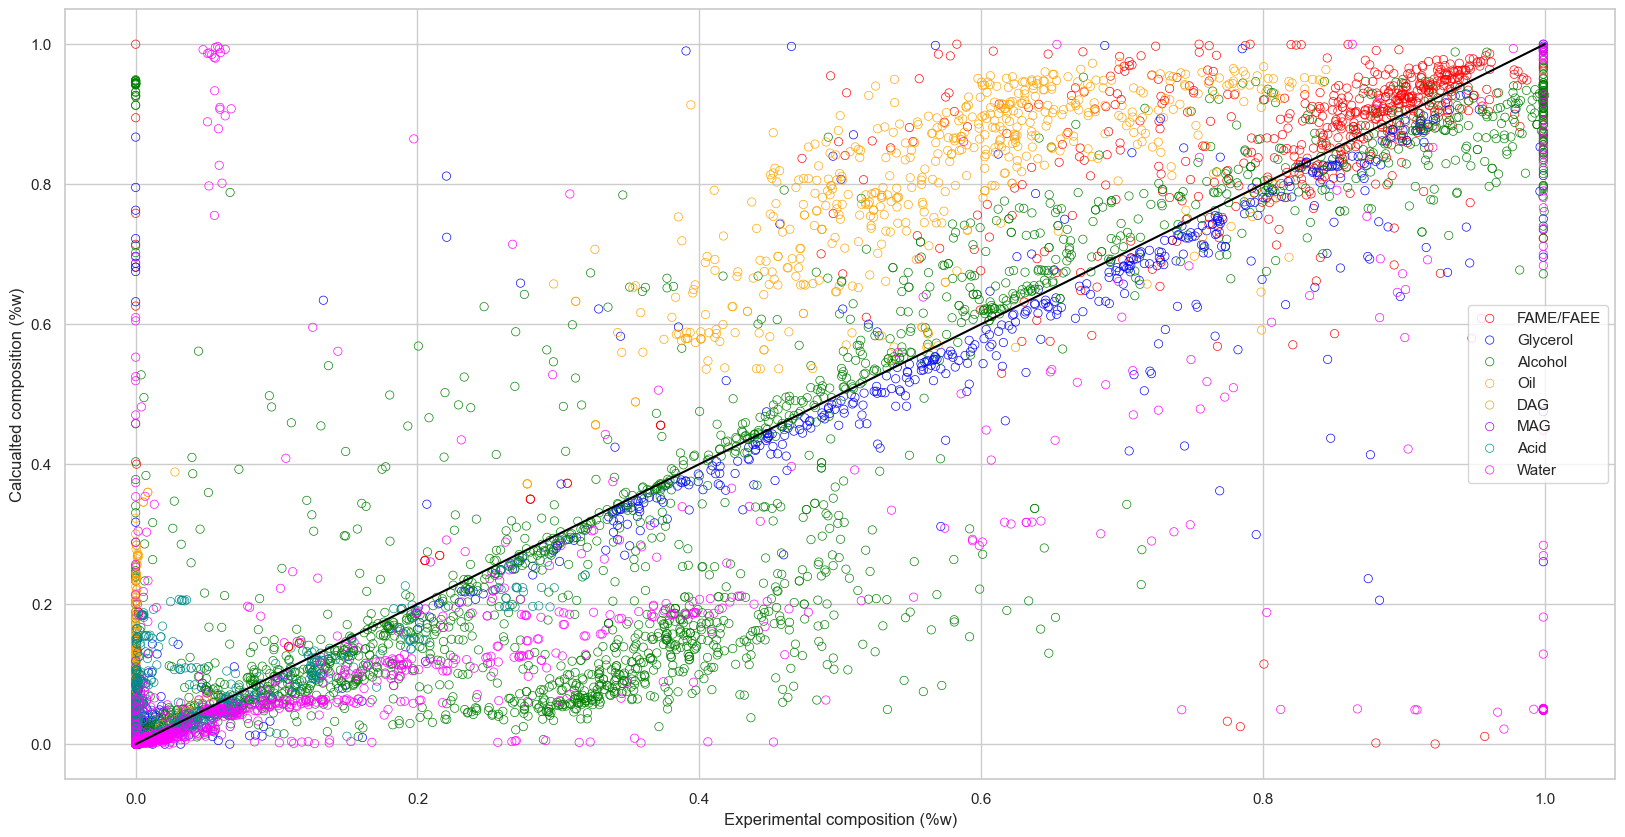

In [14]:
sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = calculated_data_np[:, 0], y = exp_compositions_np[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")
sns.scatterplot(x = calculated_data_np[:, 8], y = exp_compositions_np[:, 8], facecolor = "none", edgecolor = "red")

sns.scatterplot(x = calculated_data_np[:, 1], y = exp_compositions_np[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")
sns.scatterplot(x = calculated_data_np[:, 9], y = exp_compositions_np[:, 9], facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = calculated_data_np[:, 2], y = exp_compositions_np[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")
sns.scatterplot(x = calculated_data_np[:, 10], y = exp_compositions_np[:, 10], facecolor = "none", edgecolor = "green")

sns.scatterplot(x = calculated_data_np[:, 3], y = exp_compositions_np[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")
sns.scatterplot(x = calculated_data_np[:, 11], y = exp_compositions_np[:, 11], facecolor = "none", edgecolor = "orange")

sns.scatterplot(x = calculated_data_np[:, 4], y = exp_compositions_np[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")
sns.scatterplot(x = calculated_data_np[:, 12], y = exp_compositions_np[:, 12], facecolor = "none", edgecolor = "goldenrod")

sns.scatterplot(x = calculated_data_np[:, 5], y = exp_compositions_np[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")
sns.scatterplot(x = calculated_data_np[:, 13], y = exp_compositions_np[:, 13], facecolor = "none", edgecolor = "darkviolet")

sns.scatterplot(x = calculated_data_np[:, 6], y = exp_compositions_np[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")
sns.scatterplot(x = calculated_data_np[:, 14], y = exp_compositions_np[:, 14], facecolor = "none", edgecolor = "darkcyan")

sns.scatterplot(x = calculated_data_np[:, 7], y = exp_compositions_np[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")
sns.scatterplot(x = calculated_data_np[:, 15], y = exp_compositions_np[:, 15], facecolor = "none", edgecolor = "magenta").set(xlabel = "Experimental composition (%w)", ylabel = "Calcualted composition (%w)")
plt.show()

#### Evaluation of new params V2

In [15]:
calculated_data = pl.read_excel("results/UDortmund_Results_V2.xlsx", engine="calamine")

In [16]:
calculated_data_np = calculated_data.to_numpy()

In [17]:
total_error = np.sum((exp_compositions_np - calculated_data_np)**2)/exp_compositions.shape[0]*100
print("El error total es: ", total_error)

El error total es:  16.517546728370245


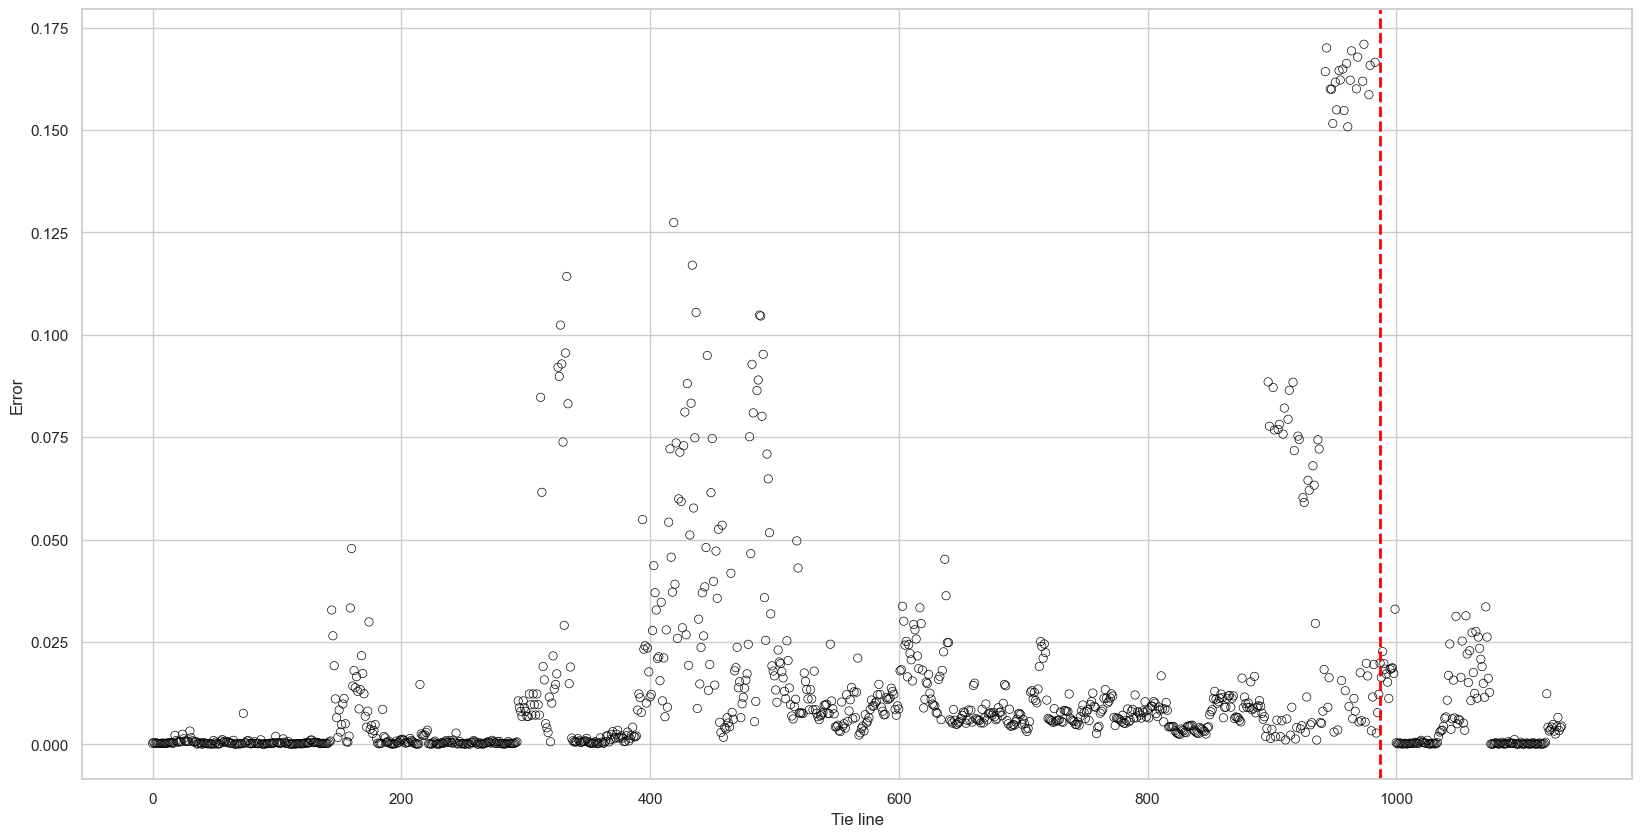

In [18]:
sns.set_theme(rc={'figure.figsize':(20,10)})
sns.set_style("whitegrid")
sns.scatterplot(x = range(exp_compositions_np.shape[0]), y =  np.sum((exp_compositions_np - calculated_data_np)**2, 1)/exp_compositions.shape[0]*100, 
                facecolor = "none", edgecolor = "black").set(xlabel = "Tie line", ylabel="Error")
plt.axvline(x=987, color='red', linestyle='--', linewidth=2)
plt.show()

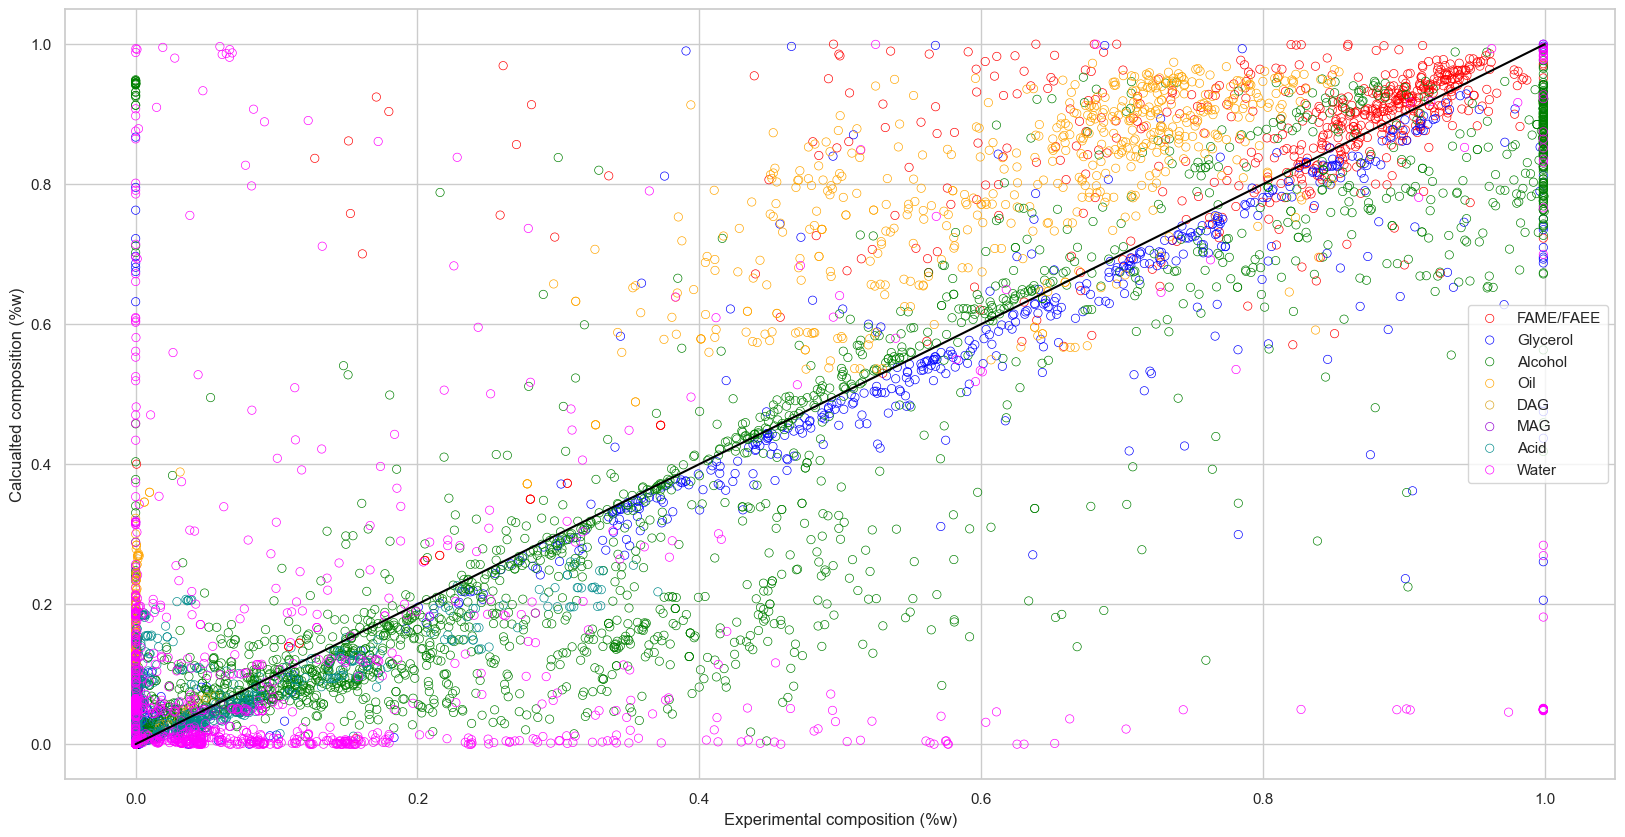

In [19]:
sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = calculated_data_np[:, 0], y = exp_compositions_np[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")
sns.scatterplot(x = calculated_data_np[:, 8], y = exp_compositions_np[:, 8], facecolor = "none", edgecolor = "red")

sns.scatterplot(x = calculated_data_np[:, 1], y = exp_compositions_np[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")
sns.scatterplot(x = calculated_data_np[:, 9], y = exp_compositions_np[:, 9], facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = calculated_data_np[:, 2], y = exp_compositions_np[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")
sns.scatterplot(x = calculated_data_np[:, 10], y = exp_compositions_np[:, 10], facecolor = "none", edgecolor = "green")

sns.scatterplot(x = calculated_data_np[:, 3], y = exp_compositions_np[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")
sns.scatterplot(x = calculated_data_np[:, 11], y = exp_compositions_np[:, 11], facecolor = "none", edgecolor = "orange")

sns.scatterplot(x = calculated_data_np[:, 4], y = exp_compositions_np[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")
sns.scatterplot(x = calculated_data_np[:, 12], y = exp_compositions_np[:, 12], facecolor = "none", edgecolor = "goldenrod")

sns.scatterplot(x = calculated_data_np[:, 5], y = exp_compositions_np[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")
sns.scatterplot(x = calculated_data_np[:, 13], y = exp_compositions_np[:, 13], facecolor = "none", edgecolor = "darkviolet")

sns.scatterplot(x = calculated_data_np[:, 6], y = exp_compositions_np[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")
sns.scatterplot(x = calculated_data_np[:, 14], y = exp_compositions_np[:, 14], facecolor = "none", edgecolor = "darkcyan")

sns.scatterplot(x = calculated_data_np[:, 7], y = exp_compositions_np[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")
sns.scatterplot(x = calculated_data_np[:, 15], y = exp_compositions_np[:, 15], facecolor = "none", edgecolor = "magenta").set(xlabel = "Experimental composition (%w)", ylabel = "Calcualted composition (%w)")
plt.show()

#### Evaluation of new params V3

In [20]:
calculated_data = pl.read_excel("results/UDortmund_Results_V3.xlsx", engine="calamine")

In [21]:
calculated_data_np = calculated_data.to_numpy()

In [22]:
total_error = np.sum((exp_compositions_np - calculated_data_np)**2)/exp_compositions.shape[0]*100
print("El error total es: ", total_error)

El error total es:  15.817077762970413


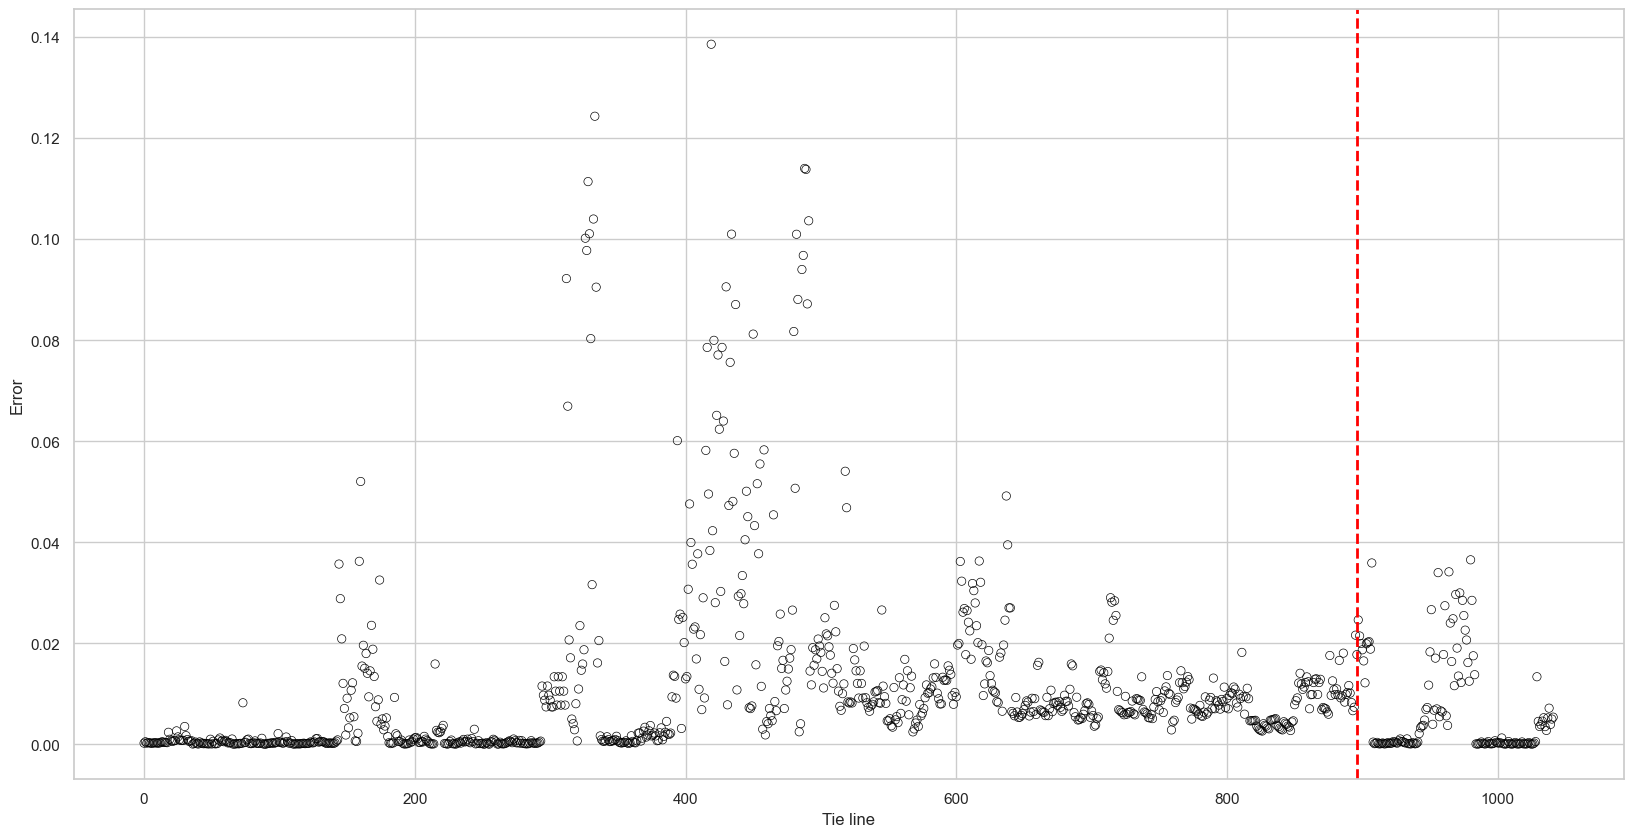

In [22]:
sns.set_theme(rc={'figure.figsize':(20,10)})
sns.set_style("whitegrid")
sns.scatterplot(x = range(exp_compositions_np.shape[0]), y =  np.sum((exp_compositions_np - calculated_data_np)**2, 1)/exp_compositions.shape[0]*100, 
                facecolor = "none", edgecolor = "black").set(xlabel = "Tie line", ylabel="Error")
plt.axvline(x=896, color='red', linestyle='--', linewidth=2)
plt.show()

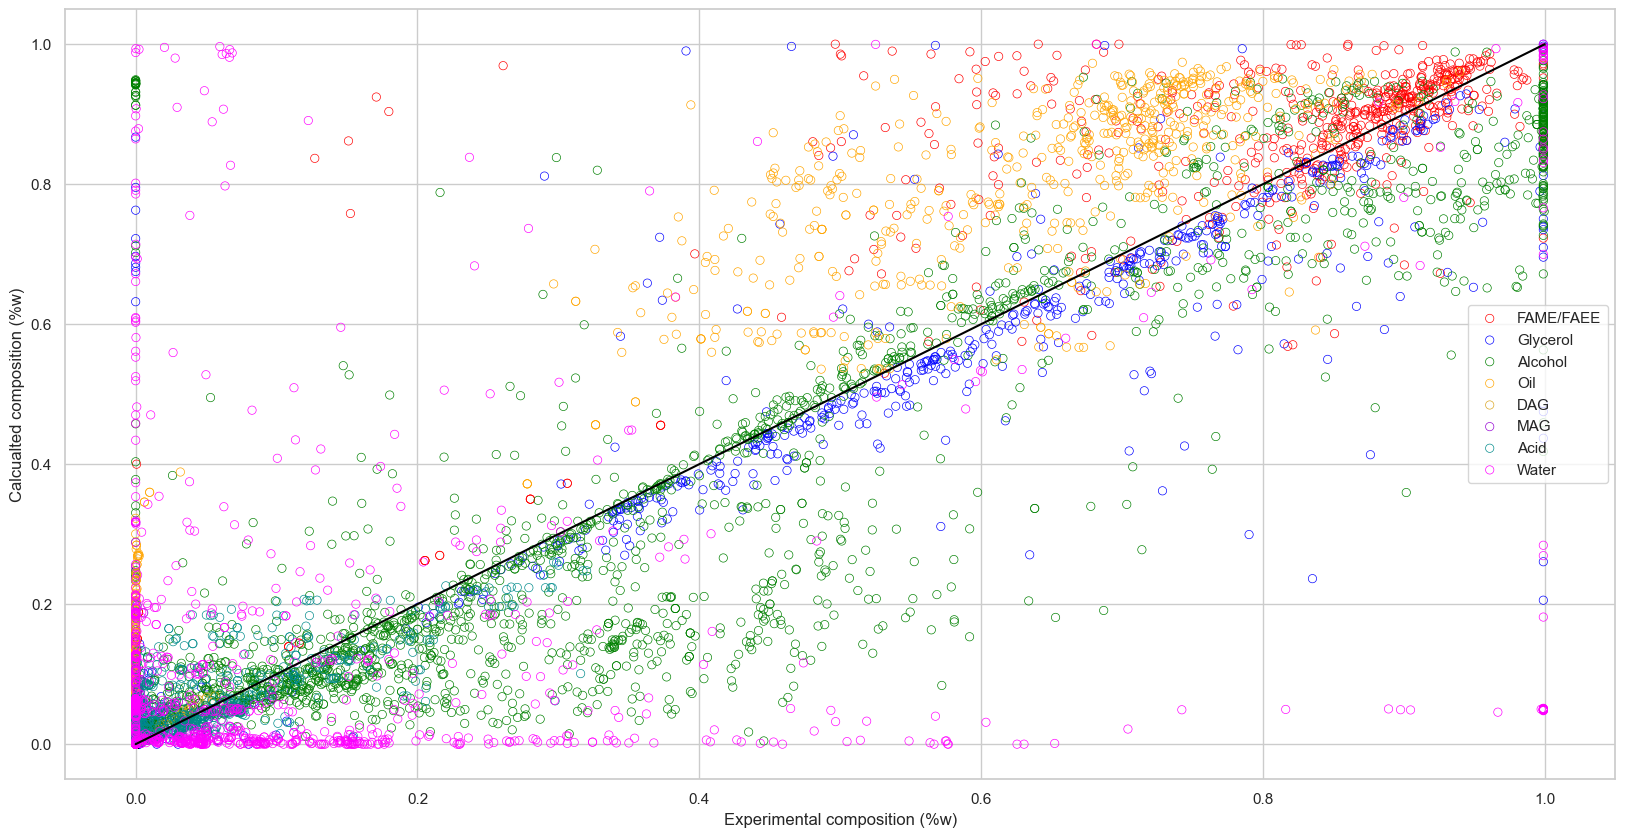

In [24]:
sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = calculated_data_np[:, 0], y = exp_compositions_np[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")
sns.scatterplot(x = calculated_data_np[:, 8], y = exp_compositions_np[:, 8], facecolor = "none", edgecolor = "red")

sns.scatterplot(x = calculated_data_np[:, 1], y = exp_compositions_np[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")
sns.scatterplot(x = calculated_data_np[:, 9], y = exp_compositions_np[:, 9], facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = calculated_data_np[:, 2], y = exp_compositions_np[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")
sns.scatterplot(x = calculated_data_np[:, 10], y = exp_compositions_np[:, 10], facecolor = "none", edgecolor = "green")

sns.scatterplot(x = calculated_data_np[:, 3], y = exp_compositions_np[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")
sns.scatterplot(x = calculated_data_np[:, 11], y = exp_compositions_np[:, 11], facecolor = "none", edgecolor = "orange")

sns.scatterplot(x = calculated_data_np[:, 4], y = exp_compositions_np[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")
sns.scatterplot(x = calculated_data_np[:, 12], y = exp_compositions_np[:, 12], facecolor = "none", edgecolor = "goldenrod")

sns.scatterplot(x = calculated_data_np[:, 5], y = exp_compositions_np[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")
sns.scatterplot(x = calculated_data_np[:, 13], y = exp_compositions_np[:, 13], facecolor = "none", edgecolor = "darkviolet")

sns.scatterplot(x = calculated_data_np[:, 6], y = exp_compositions_np[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")
sns.scatterplot(x = calculated_data_np[:, 14], y = exp_compositions_np[:, 14], facecolor = "none", edgecolor = "darkcyan")

sns.scatterplot(x = calculated_data_np[:, 7], y = exp_compositions_np[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")
sns.scatterplot(x = calculated_data_np[:, 15], y = exp_compositions_np[:, 15], facecolor = "none", edgecolor = "magenta").set(xlabel = "Experimental composition (%w)", ylabel = "Calcualted composition (%w)")
plt.show()

#### Evaluation of new params V4 (After remove exp 47)

In [3]:
calculated_data = pl.read_excel("results/UDortmund_Results_V5.xlsx", engine="calamine")

In [4]:
calculated_data_np = calculated_data.to_numpy()

In [5]:
total_error = root_mean_squared_error(exp_compositions_np, calculated_data_np)
print("RMSE: ", total_error)

RMSE:  0.06678978351139582


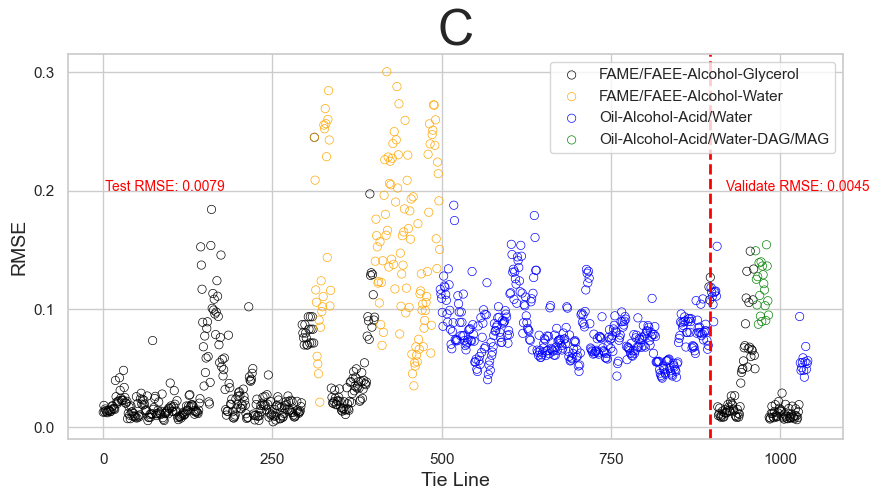

In [8]:
sns.set_theme(rc={'figure.figsize':(10,5)})
sns.set_style("whitegrid")

sns.scatterplot(x = range(313), y =  np.sqrt(np.mean((exp_compositions_np[0:313, :] - calculated_data_np[0:313, :])**2, 1)), 
                facecolor = "none", edgecolor = "black", label = "FAME/FAEE-Alcohol-Glycerol")

sns.scatterplot(x = range(312, 337, 1), y =  np.sqrt(np.mean((exp_compositions_np[312:337, :] - calculated_data_np[312:337, :])**2, 1)), 
                facecolor = "none", edgecolor = "Orange", label = "FAME/FAEE-Alcohol-Water")

sns.scatterplot(x = range(337, 402, 1), y =  np.sqrt(np.mean((exp_compositions_np[337:402, :] - calculated_data_np[337:402, :])**2, 1)), 
                facecolor = "none", edgecolor = "Black")

sns.scatterplot(x = range(402, 498, 1), y =  np.sqrt(np.mean((exp_compositions_np[402:498, :] - calculated_data_np[402:498, :])**2, 1)), 
                facecolor = "none", edgecolor = "Orange")

sns.scatterplot(x = range(498, 895, 1), y =  np.sqrt(np.mean((exp_compositions_np[498:895, :] - calculated_data_np[498:895, :])**2, 1)), 
                facecolor = "none", edgecolor = "blue", label = "Oil-Alcohol-Acid/Water")

sns.scatterplot(x = range(895, 898, 1), y =  np.sqrt(np.mean((exp_compositions_np[895:898, :] - calculated_data_np[895:898, :])**2, 1)), 
                facecolor = "none", edgecolor = "black")

sns.scatterplot(x = range(898, 908, 1), y =  np.sqrt(np.mean((exp_compositions_np[898:908, :] - calculated_data_np[898:908, :])**2, 1)), 
                facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = range(908, 964, 1), y =  np.sqrt(np.mean((exp_compositions_np[908:964, :] - calculated_data_np[908:964, :])**2, 1)), 
                facecolor = "none", edgecolor = "black")

sns.scatterplot(x = range(964, 984, 1), y =  np.sqrt(np.mean((exp_compositions_np[964:984, :] - calculated_data_np[964:984, :])**2, 1)), 
                facecolor = "none", edgecolor = "green", label = "Oil-Alcohol-Acid/Water-DAG/MAG")

sns.scatterplot(x = range(984, 1029, 1), y =  np.sqrt(np.mean((exp_compositions_np[984:1029, :] - calculated_data_np[984:1029, :])**2, 1)), 
                facecolor = "none", edgecolor = "black")

sns.scatterplot(x = range(1029, 1042, 1), y =  np.sqrt(np.mean((exp_compositions_np[1029:1042, :] - calculated_data_np[1029:1042, :])**2, 1)), 
                facecolor = "none", edgecolor = "blue")

test_RMSE = round(np.mean((exp_compositions_np[:897, :] - calculated_data_np[:897, :])**2), 4)
validate_RMSE = round(np.mean((exp_compositions_np[896:, :] - calculated_data_np[896:, :])**2), 4)
plt.text(2, 0.2, f'Test RMSE: {test_RMSE}', fontsize=10, color='red')
plt.text(920, 0.2, f'Validate RMSE: {validate_RMSE}', fontsize=10, color='red')

plt.axvline(x=896, color='red', linestyle='--', linewidth=2)
plt.legend(loc = "upper right")
plt.xlabel("Tie Line", fontsize=14)
plt.ylabel("RMSE", fontsize=14)
sns.set_context("talk", font_scale=2)  

plt.title("C")
plt.savefig('UNIFACD_RMSE_V2.png', dpi=1000, bbox_inches='tight')
plt.show()

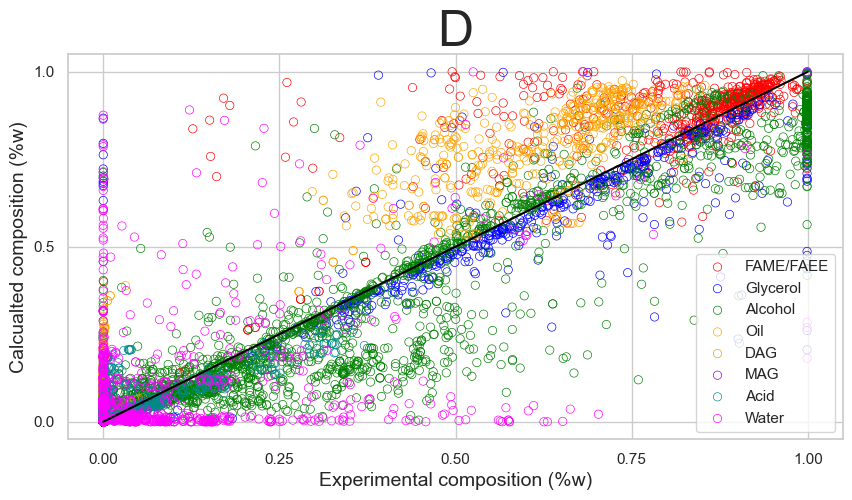

In [9]:
sns.set_theme(rc={'figure.figsize':(10,5)})
sns.set_style("whitegrid")

sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = calculated_data_np[:, 0], y = exp_compositions_np[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")
sns.scatterplot(x = calculated_data_np[:, 8], y = exp_compositions_np[:, 8], facecolor = "none", edgecolor = "red")

sns.scatterplot(x = calculated_data_np[:, 1], y = exp_compositions_np[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")
sns.scatterplot(x = calculated_data_np[:, 9], y = exp_compositions_np[:, 9], facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = calculated_data_np[:, 2], y = exp_compositions_np[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")
sns.scatterplot(x = calculated_data_np[:, 10], y = exp_compositions_np[:, 10], facecolor = "none", edgecolor = "green")

sns.scatterplot(x = calculated_data_np[:, 3], y = exp_compositions_np[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")
sns.scatterplot(x = calculated_data_np[:, 11], y = exp_compositions_np[:, 11], facecolor = "none", edgecolor = "orange")

sns.scatterplot(x = calculated_data_np[:, 4], y = exp_compositions_np[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")
sns.scatterplot(x = calculated_data_np[:, 12], y = exp_compositions_np[:, 12], facecolor = "none", edgecolor = "goldenrod")

sns.scatterplot(x = calculated_data_np[:, 5], y = exp_compositions_np[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")
sns.scatterplot(x = calculated_data_np[:, 13], y = exp_compositions_np[:, 13], facecolor = "none", edgecolor = "darkviolet")

sns.scatterplot(x = calculated_data_np[:, 6], y = exp_compositions_np[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")
sns.scatterplot(x = calculated_data_np[:, 14], y = exp_compositions_np[:, 14], facecolor = "none", edgecolor = "darkcyan")

sns.scatterplot(x = calculated_data_np[:, 7], y = exp_compositions_np[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")
sns.scatterplot(x = calculated_data_np[:, 15], y = exp_compositions_np[:, 15], facecolor = "none", edgecolor = "magenta")

plt.xlabel("Experimental composition (%w)", fontsize=14)
plt.ylabel("Calcualted composition (%w)", fontsize=14)
sns.set_context("talk", font_scale=2) 

plt.title("D")
plt.savefig('UNIFACD_CORR_V2.png', dpi=1000, bbox_inches='tight')
plt.show()


#### Results with convergence algorithm

#### UNIFAC

##### Random data initialization

In [6]:
exp_compositions_np = load_real_data(r"D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\ExperimentalData\data\No 47exp\refined_lle_data_v4.xlsx")
calculated_data_np = load_predicted_data(r"D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\Evaluation\Deterministic_optimization\results 2 attempt\prediction_results\results_predict_total_UNIFAC_random_init.xlsx")

In [7]:
total_error = root_mean_squared_error(exp_compositions_np, calculated_data_np)
print("RMSE: ", total_error)

RMSE:  0.1563000153717254


C:\Users\juand\AppData\Local\Temp\ipykernel_24712\2626710372.py:43: RuntimeWarning: invalid value encountered in sqrt
  sns.scatterplot(x = range(964, 984, 1), y =  np.sqrt(np.mean((exp_compositions_np[964:984, :] - calculated_data_np[964:984, :]), 1)),


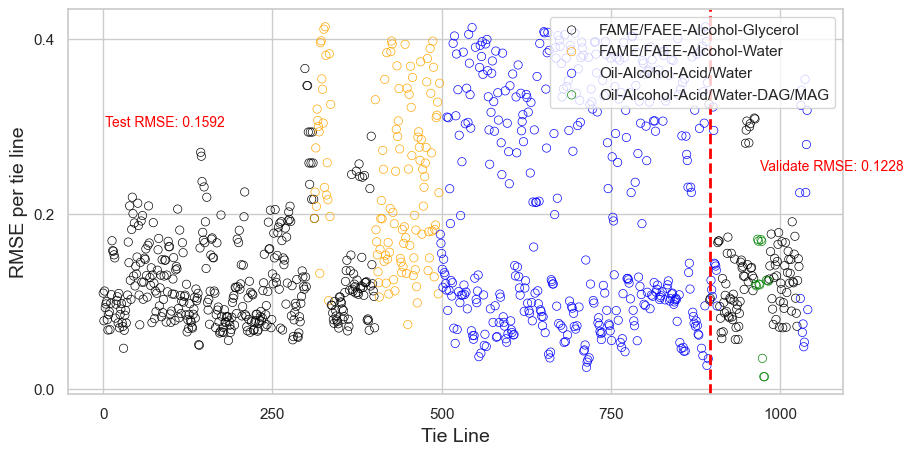

In [9]:
error_graph(exp_compositions_np, calculated_data_np)

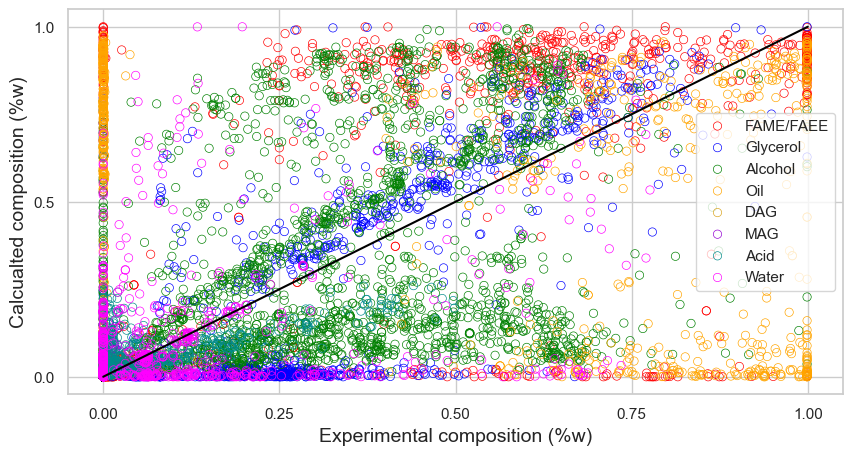

In [12]:
deviation_grahp(exp_compositions_np, calculated_data_np)

##### Exp data initialization

In [14]:
calculated_data_np = load_predicted_data(r"D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\Evaluation\Deterministic_optimization\results 2 attempt\prediction_results\results_predict_total_UNIFAC.xlsx")

In [15]:
total_error = root_mean_squared_error(exp_compositions_np, calculated_data_np)
print("RMSE: ", total_error)

RMSE:  0.1270680569925649


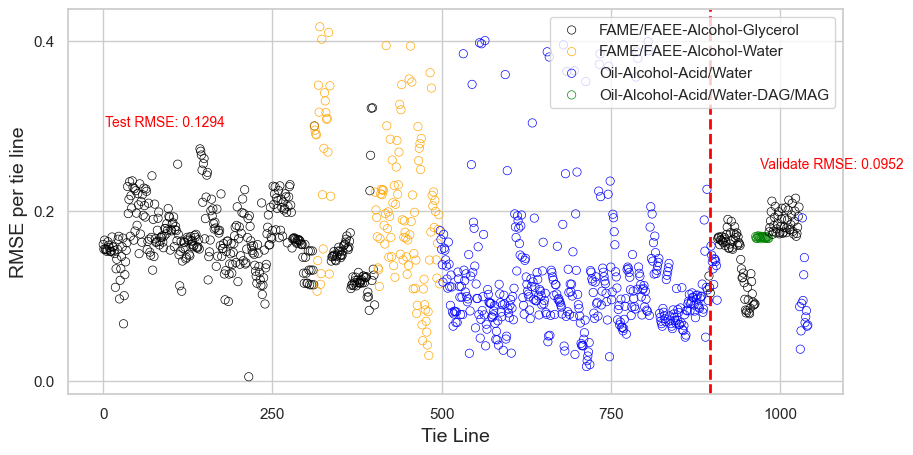

In [16]:
error_graph(exp_compositions_np, calculated_data_np)

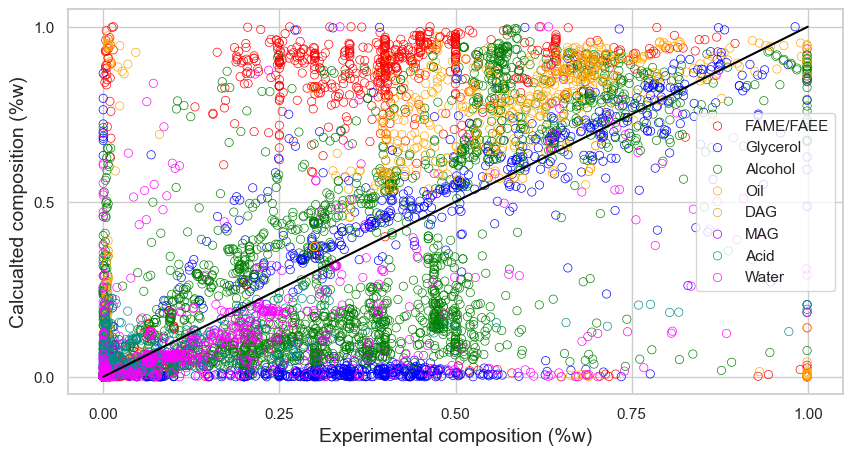

In [17]:
deviation_grahp(exp_compositions_np, calculated_data_np)

#### UNIFAC Dortmund

##### Random data initialization

In [19]:
calculated_data_np = load_predicted_data(r"D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\Evaluation\Deterministic_optimization\results 2 attempt\prediction_results\results_predict_total_UNIFACD_random_initV2.xlsx")

In [20]:
total_error = root_mean_squared_error(exp_compositions_np, calculated_data_np)
print("RMSE: ", total_error)

RMSE:  0.15822826797564613


C:\Users\juand\AppData\Local\Temp\ipykernel_24712\4247093882.py:43: RuntimeWarning: invalid value encountered in sqrt
  sns.scatterplot(x = range(964, 984, 1), y =  np.sqrt(np.mean((exp_compositions_np[964:984, :] - calculated_data_np[964:984, :]), 1)),


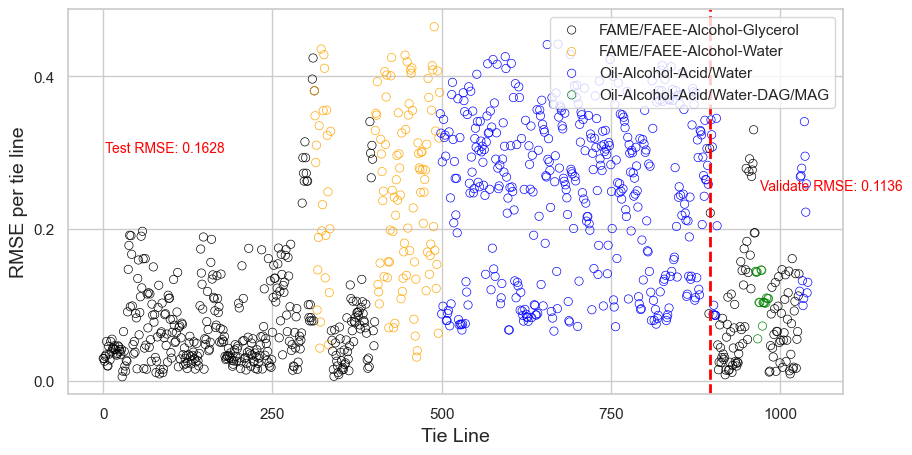

In [21]:
error_graph(exp_compositions_np, calculated_data_np)

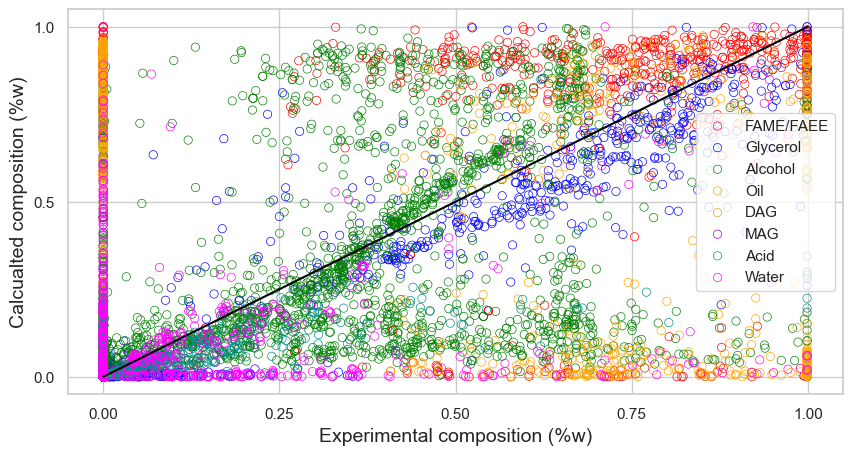

In [22]:
deviation_grahp(exp_compositions_np, calculated_data_np)

##### Exp data initialization

In [23]:
calculated_data_np = load_predicted_data(r"D:\Juan\proyectos_personales\Maestría\Materias\Tesis\oleosim\Evaluation\Deterministic_optimization\results 2 attempt\prediction_results\results_predict_total_V2.xlsx")

In [24]:
total_error = root_mean_squared_error(exp_compositions_np, calculated_data_np)
print("RMSE: ", total_error)

RMSE:  0.1338698950358837


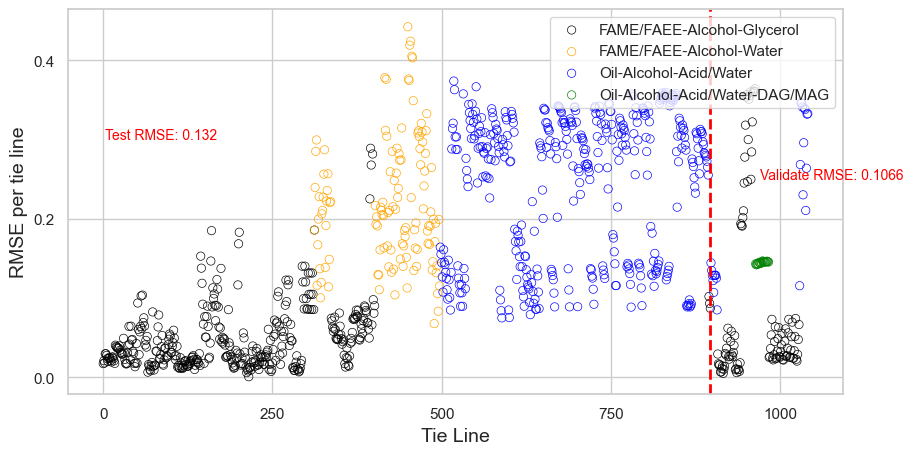

In [28]:
error_graph(exp_compositions_np, calculated_data_np)

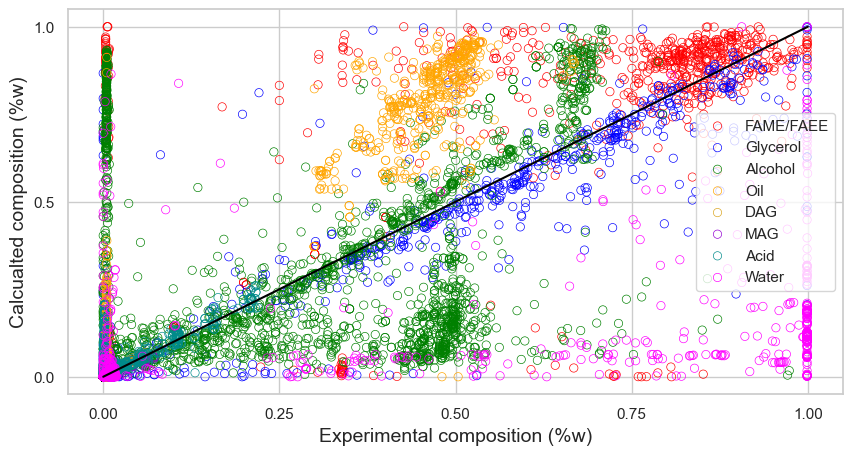

In [29]:
deviation_grahp(exp_compositions_np, calculated_data_np)